# PRAKTIKUM 03 — Data Preprocessing

**Seri:** *From Data to Machine Learning*  
**Level:** Dasar–menengah awal | **Durasi anjuran:** 120 menit praktik terbimbing + latihan mandiri  
**Dataset utama:** `Data.csv` (10 baris, 4 kolom) dari paket workshop asli.  
**Fokus:** kualitas data, *train–test split*, imputasi, *feature scaling*, pengodean kategori dalam pipeline, transformasi data baru, dan pencegahan *data leakage*.

> **Batas antarpraktikum:** Praktikum 01 membahas Python dan eksplorasi data; Praktikum 02 membahas representasi fitur tabular/teks/citra. Di **Praktikum 03**, kita menyiapkan dataset **dengan prosedur fit/transform yang benar**. Pelatihan dan evaluasi model klasifikasi dibahas pada Praktikum 04.

**Petunjuk:** Jalankan **Kernel → Restart & Run All** dari awal. Pelajari setiap tabel, grafik, dan interpretasi sebelum melanjutkan. Latihan serta kunci jawaban dipisahkan pada bagian akhir.

**Batasan contoh:** `Data.csv` hanya berisi **10 observasi**, sehingga dipakai untuk **memahami mekanisme**, bukan untuk menyimpulkan mutu model atau generalisasi statistik.

## A. Capaian pembelajaran dan peta materi

Setelah menyelesaikan praktikum, mahasiswa dapat:

1. Mengidentifikasi tipe fitur, target, nilai hilang, baris duplikat, dan nilai yang perlu ditinjau.
2. Memisahkan data menjadi *training* dan *testing* dengan `random_state` serta memahami tujuan stratifikasi.
3. Menjelaskan perbedaan `fit()`, `transform()`, dan `fit_transform()` serta menghindari *data leakage*.
4. Menerapkan imputasi median untuk variabel numerik dan modus untuk kategori; menjelaskan keterbatasannya.
5. Membandingkan **StandardScaler**, **MinMaxScaler**, dan **RobustScaler**, termasuk pengaruh nilai ekstrem.
6. Membangun `Pipeline` dan `ColumnTransformer` untuk menangani numerik dan kategorikal secara terpadu.
7. Menghasilkan *final feature matrix* train/test dengan nama fitur yang konsisten, serta memproses satu record baru.
8. Mengerjakan dan menjelaskan latihan berdasarkan hasil pengamatan, bukan sekadar menyalin kode.

**Alur:** `Audit → Tentukan X/y → Split → Imputasi → Scaling → Pipeline → Transform test dan sampel baru → Audit hasil → Latihan → Kunci jawaban`.

**Perhatian:** Rangkaian eksperimen terpisah digunakan untuk menjelaskan konsep. Pada aplikasi nyata, gunakan pipeline yang di-*fit* **hanya pada data train**.

## B. Persiapan lingkungan dan dataset

Pustaka: Python 3.10+, `numpy`, `pandas`, `matplotlib`, `scikit-learn`, dan Jupyter/IPython. Untuk instalasi awal, jalankan di terminal:

```bash
python -m pip install numpy pandas matplotlib scikit-learn jupyterlab
```

Struktur ZIP mandiri:

```text
Praktikum_03/
├── 03_Preprocessing_Data_Modul_Final_dan_Jawaban.ipynb
├── README.txt
└── data/
    └── Data.csv
```

Notebook juga dapat dijalankan dari dalam paket workshop asli (`praktikum/data/Data.csv`). **Tidak ada data simulasi untuk menggantikan `Data.csv` secara diam-diam.** Percobaan angka ekstrem pada bagian G dinyatakan sebagai eksperimen sintetis terpisah.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

CANDIDATES = [Path.cwd(), *Path.cwd().parents]
SUBDIRS = (Path('data'), Path('praktikum/data'),
           Path('Workshop_From_Data_to_ML/praktikum/data'))
DATA_DIR = next((base / sub for base in CANDIDATES for sub in SUBDIRS
                 if (base / sub / 'Data.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        'Data.csv tidak ditemukan. Simpan pada folder data/ di samping notebook, '
        'atau jalankan di dalam direktori paket workshop asli.'
    )
DATA_PATH = DATA_DIR / 'Data.csv'
print('Python      :', sys.version.split()[0])
print('Data Source :', DATA_PATH.resolve())
print('File bytes  :', DATA_PATH.stat().st_size)

Python      : 3.10.18
Data Source : /Users/masaboe/Documents/NGAJAR/ngudiWaluyo2026/final_release/Workshop_From_Data_to_ML/praktikum/data/Data.csv
File bytes  : 216


## C. Data quality assessment: memahami data sebelum diubah

Tahap ini disebut **audit awal**. Jangan langsung mengisi `NaN` atau menghapus baris tanpa melihat penyebab dan dampaknya.

Dataset memiliki tiga calon fitur:
- `Country` → kategorikal nominal.
- `Age` → numerik (usia).
- `Salary` → numerik (estimasi gaji).

`Purchased` adalah **target** (`No`/`Yes`), bukan fitur input. Masing-masing baris adalah satu observasi. Data asli dapat memuat nilai yang hilang; kekosongan berbeda dengan angka `0`.

In [2]:
data = pd.read_csv(DATA_PATH)
EXPECTED = {'Country', 'Age', 'Salary', 'Purchased'}
if not EXPECTED.issubset(data.columns):
    raise ValueError(f'Kolom yang diperlukan tidak lengkap: {EXPECTED - set(data.columns)}')
print('=== Data asli ===')
display(data)
print('Shape:', data.shape)
print('Tipe data:')
display(data.dtypes.to_frame('dtype'))

=== Data asli ===


,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,NaN,Yes
5,France,35.0,58000.0,Yes
6,Spain,NaN,52000.0,No
7,France,48.0,79000.0,Yes
8,Germany,50.0,83000.0,No
9,France,37.0,67000.0,Yes


Shape: (10, 4)
Tipe data:


,dtype
Country,object
Age,float64
Salary,float64
Purchased,object


### C1. Mengecek nilai kosong dan baris duplikat

Pemeriksaan minimal: `isna().sum()` (jumlah nilai hilang), persentase `isna().mean() * 100`, serta `duplicated().sum()` (duplikat baris utuh). **Duplikat tidak otomatis salah**; periksa identitas dan konteks sebelum menghapusnya.

In [3]:
audit = pd.DataFrame({
    'dtype': data.dtypes.astype(str),
    'missing_n': data.isna().sum(),
    'missing_pct': (data.isna().mean() * 100).round(1),
    'unique_non_null': data.nunique(dropna=True)
})
print('=== Audit kolom ===')
display(audit)
print('Jumlah baris duplikat utuh:', int(data.duplicated().sum()))
print('Baris yang memiliki setidaknya satu nilai kosong:')
display(data.loc[data.isna().any(axis=1)])

=== Audit kolom ===


,dtype,missing_n,missing_pct,unique_non_null
Country,object,0,0.0,3
Age,float64,1,10.0,9
Salary,float64,1,10.0,9
Purchased,object,0,0.0,2


Jumlah baris duplikat utuh: 0
Baris yang memiliki setidaknya satu nilai kosong:


,Country,Age,Salary,Purchased
4,Germany,40.0,NaN,Yes
6,Spain,NaN,52000.0,No


### C2. Visualisasi lokasi missing values

Setiap sel pada gambar menunjukkan apakah suatu nilai hilang atau tidak. Grafik ini **bukan grafik korelasi**; tujuannya menemukan posisi missing value secara cepat.

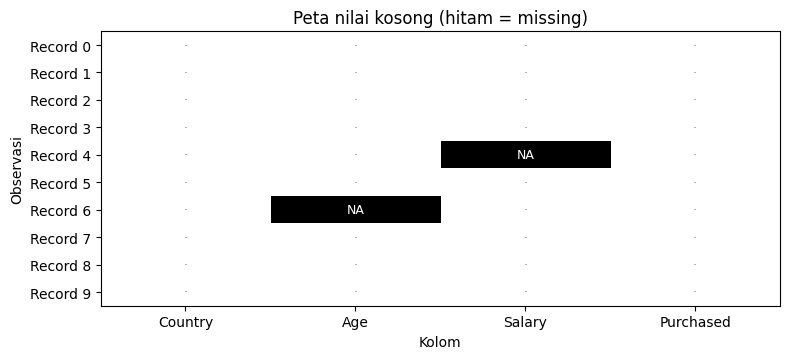

In [4]:
mask = data.isna().astype(int)
fig, ax = plt.subplots(figsize=(8, 3.7))
image = ax.imshow(mask.to_numpy(), cmap='Greys', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(data.columns)), data.columns)
ax.set_yticks(range(len(data)), [f'Record {i}' for i in data.index])
ax.set_xlabel('Kolom')
ax.set_ylabel('Observasi')
ax.set_title('Peta nilai kosong (hitam = missing)')
for row in range(mask.shape[0]):
    for col in range(mask.shape[1]):
        ax.text(col, row, 'NA' if mask.iat[row, col] else '·',
                ha='center', va='center',
                color='white' if mask.iat[row, col] else 'grey', fontsize=9)
plt.tight_layout()
plt.show()

### C3. Statistik dan validitas sederhana

Statistik ringkas membantu melihat rentang dan kemungkinan nilai tidak wajar. Kita bisa mendeteksi nilai yang perlu **ditinjau**, tetapi tidak dapat memastikan suatu data salah hanya dari boxplot. Pengetahuan domain dan aturan pencatatan tetap diperlukan.

In [5]:
display(data[['Age', 'Salary']].describe().round(2))
print('Negara yang tercatat:', sorted(data['Country'].dropna().unique()))
print('Target:')
display(data['Purchased'].value_counts(dropna=False).to_frame('jumlah'))
print('Jumlah usia negatif (jika ada):', int((data['Age'] < 0).sum()))
print('Jumlah Salary negatif (jika ada):', int((data['Salary'] < 0).sum()))

,Age,Salary
count,9.00,9.00
mean,38.78,63777.78
std,7.69,12265.58
min,27.00,48000.00
25%,35.00,54000.00
50%,38.00,61000.00
75%,44.00,72000.00
max,50.00,83000.00


Negara yang tercatat: ['France', 'Germany', 'Spain']
Target:


,jumlah
Purchased,
No,5
Yes,5


Jumlah usia negatif (jika ada): 0
Jumlah Salary negatif (jika ada): 0


### C4. Pemeriksaan outlier sebagai penanda investigasi (bukan pembersihan otomatis)

Aturan IQR menggunakan `Q1 − 1.5 × IQR` dan `Q3 + 1.5 × IQR` sebagai batas *flag*. Pada dataset yang kecil, penanda IQR tidak stabil; hasilnya hanya informasi tambahan.

Age: lower=21.50, upper=57.50, ditandai=0 record
Salary: lower=27,000.00, upper=99,000.00, ditandai=0 record


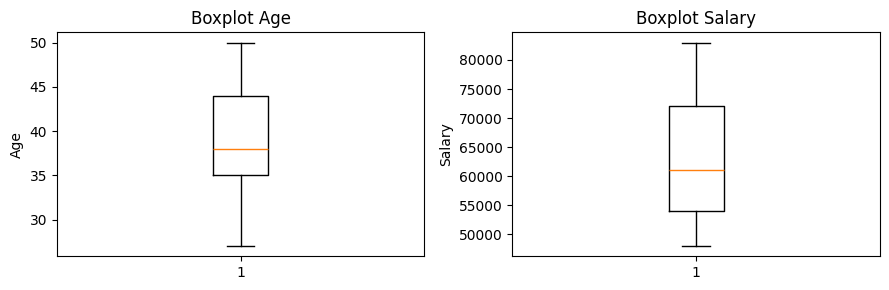

In [6]:
def iqr_flags(series):
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return lower, upper, series.lt(lower) | series.gt(upper)

for feature in ['Age', 'Salary']:
    lower, upper, flag = iqr_flags(data[feature])
    print(f'{feature}: lower={lower:,.2f}, upper={upper:,.2f}, '
          f'ditandai={int(flag.sum())} record')

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, feature in zip(axes, ['Age', 'Salary']):
    ax.boxplot(data[feature].dropna(), vert=True)
    ax.set_title(f'Boxplot {feature}')
    ax.set_ylabel(feature)
plt.tight_layout()
plt.show()

### C5. Keputusan awal berbasis hasil audit

Untuk latihan ini, strategi yang dipilih adalah:

| Kondisi | Keputusan praktikum | Alasan |
|---|---|---|
| `Age` kosong | **Imputasi median** dari train | Dapat digunakan meski distribusi tidak simetris |
| `Salary` kosong | **Imputasi median** dari train | Menunjukkan parameter statistik yang dipelajari |
| `Country` kategori teks | **Imputasi modus + One-Hot Encoding** pada pipeline | Menjaga format numerik dan kolom tetap konsisten |
| `Purchased` | Dipisahkan menjadi `y` | Mencegah target masuk ke fitur |
| Outlier yang ditandai | Tidak dihapus otomatis | Perlu validasi domain dan ukuran sampel |

**Penting:** Audit deskriptif boleh digunakan untuk memahami dataset, tetapi angka imputasi, rentang min–max, rerata, simpangan baku, dan kategori encoder untuk evaluasi harus **dipelajari dari training saja**.

## D. Pisahkan fitur (`X`) dan target (`y`), lalu split

Mengapa pembagian dilakukan **sebelum** `fit` preprocessing? Karena data test harus menjadi sampel yang tidak ikut menentukan parameter transformasi. Jika test ikut membentuk median atau skala, terjadi **data leakage**.

Kita menggunakan `stratify=y` agar proporsi kelas diusahakan seimbang dalam train dan test; pada dataset 10 baris, tiap satu observasi dapat mengubah proporsi secara besar. `random_state=42` membuat hasil pembagian dapat diulang.

In [7]:
FEATURES = ['Country', 'Age', 'Salary']
TARGET = 'Purchased'
X = data[FEATURES].copy()
y = data[TARGET].map({'No': 0, 'Yes': 1})
if y.isna().any():
    raise ValueError('Target mengandung nilai yang belum terpetakan. Audit label dahulu.')
y = y.astype(int)

print('X.shape:', X.shape, '| y.shape:', y.shape)
print('Fitur:', list(X.columns))
print('Distribusi label (0=No, 1=Yes):')
display(y.value_counts().sort_index().to_frame('jumlah'))

X.shape: (10, 3) | y.shape: (10,)
Fitur: ['Country', 'Age', 'Salary']
Distribusi label (0=No, 1=Yes):


,jumlah
Purchased,
0,5
1,5


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Index train:', X_train.index.to_list())
print('Index test :', X_test.index.to_list())
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(X)

print('\nDistribusi kelas setelah split:')
display(pd.DataFrame({
    'semua': y.value_counts(),
    'train': y_train.value_counts(),
    'test': y_test.value_counts()
}).fillna(0).astype(int).sort_index())

Train: (7, 3) | Test: (3, 3)
Index train: [4, 8, 2, 7, 5, 1, 3]
Index test : [0, 6, 9]

Distribusi kelas setelah split:


,semua,train,test
Purchased,,,
0,5,3,2
1,5,4,1


### D1. Audit missing value **per partisi**

Catatan penting: nilai `Age` yang hilang dapat berada di test, sedangkan nilai `Salary` yang hilang dapat berada di train. Bila fitur test tidak kosong, tetap tidak boleh menghitung statistiknya untuk membantu train.

In [9]:
print('=== Data TRAIN ===')
display(X_train.sort_index())
print('=== Data TEST ===')
display(X_test.sort_index())
print('Missing train:')
display(X_train.isna().sum().to_frame('jumlah'))
print('Missing test:')
display(X_test.isna().sum().to_frame('jumlah'))

=== Data TRAIN ===


,Country,Age,Salary
1,Spain,27.0,48000.0
2,Germany,30.0,54000.0
3,Spain,38.0,61000.0
4,Germany,40.0,NaN
5,France,35.0,58000.0
7,France,48.0,79000.0
8,Germany,50.0,83000.0


=== Data TEST ===


,Country,Age,Salary
0,France,44.0,72000.0
6,Spain,NaN,52000.0
9,France,37.0,67000.0


Missing train:


,jumlah
Country,0
Age,0
Salary,1


Missing test:


,jumlah
Country,0
Age,1
Salary,0


## E. Imputasi data: parameter dipelajari dari train

`SimpleImputer(strategy='median')` menyimpan median per fitur ketika `fit(X_train)`. Saat `transform(X_test)`, median yang sama dipakai tanpa menghitung ulang.

Untuk kategori, `most_frequent` menggunakan kategori tersering pada train (jika seri, implementasi memilih salah satu secara deterministik). Ini bukan bukti kategori tersebut paling benar secara semantik.

In [10]:
NUM_COLS = ['Age', 'Salary']
CAT_COLS = ['Country']

num_imputer_demo = SimpleImputer(strategy='median')
train_num_imputed = num_imputer_demo.fit_transform(X_train[NUM_COLS])
test_num_imputed = num_imputer_demo.transform(X_test[NUM_COLS])

print('Median TRAIN per fitur:')
display(pd.Series(num_imputer_demo.statistics_, index=NUM_COLS, name='median_train'))
print('=== Train numerik setelah imputasi ===')
display(pd.DataFrame(train_num_imputed, columns=NUM_COLS,
                     index=X_train.index).sort_index())
print('=== Test numerik setelah imputasi (median dari train) ===')
display(pd.DataFrame(test_num_imputed, columns=NUM_COLS,
                     index=X_test.index).sort_index())

Median TRAIN per fitur:


Age          38.0
Salary    59500.0
Name: median_train, dtype: float64

=== Train numerik setelah imputasi ===


,Age,Salary
1,27.0,48000.0
2,30.0,54000.0
3,38.0,61000.0
4,40.0,59500.0
5,35.0,58000.0
7,48.0,79000.0
8,50.0,83000.0


=== Test numerik setelah imputasi (median dari train) ===


,Age,Salary
0,44.0,72000.0
6,38.0,52000.0
9,37.0,67000.0


### E1. Perbandingan record yang sebelumnya kosong

Untuk memverifikasi imputasi, bandingkan `X_test` sebelum dan sesudah transformasi. Kita juga menguji bahwa tidak ada `NaN` pada kedua array hasil imputasi.

In [11]:
test_num_clean = pd.DataFrame(test_num_imputed, index=X_test.index, columns=NUM_COLS)
comparison_test = pd.concat([
    X_test[NUM_COLS].add_prefix('sebelum_'),
    test_num_clean.add_prefix('sesudah_')
], axis=1)
display(comparison_test.sort_index())
assert not np.isnan(train_num_imputed).any()
assert not np.isnan(test_num_imputed).any()
print('Checkpoint imputasi: semua fitur numerik train/test terisi.')

,sebelum_Age,sebelum_Salary,sesudah_Age,sesudah_Salary
0,44.0,72000.0,44.0,72000.0
6,NaN,52000.0,38.0,52000.0
9,37.0,67000.0,37.0,67000.0


Checkpoint imputasi: semua fitur numerik train/test terisi.


### E2. Mean, median, dan mode: bedakan jenis statistiknya

- **Mean**: rata-rata nilai, dapat sensitif terhadap nilai ekstrem.
- **Median**: nilai tengah, lebih tahan terhadap nilai ekstrem.
- **Most frequent**: kategori yang paling sering muncul.

Kita **tidak** menggunakan nilai statistik seluruh dataset untuk mengisi test.

In [12]:
train_stats = pd.DataFrame({
    'mean_train': X_train[NUM_COLS].mean(),
    'median_train': X_train[NUM_COLS].median(),
    'mean_semua_HANYA_PERBANDINGAN': X[NUM_COLS].mean(),
    'median_semua_HANYA_PERBANDINGAN': X[NUM_COLS].median()
})
display(train_stats.round(2))
cat_imp_demo = SimpleImputer(strategy='most_frequent')
cat_imp_demo.fit(X_train[CAT_COLS])
print('Modus Country yang disimpan:', cat_imp_demo.statistics_[0])
print('Nilai statistik SELURUH data hanya untuk demonstrasi leakage, tidak digunakan.')

,mean_train,median_train,mean_semua_HANYA_PERBANDINGAN,median_semua_HANYA_PERBANDINGAN
Age,38.29,38.0,38.78,38.0
Salary,63833.33,59500.0,63777.78,61000.0


Modus Country yang disimpan: Germany
Nilai statistik SELURUH data hanya untuk demonstrasi leakage, tidak digunakan.


## F. Scaling: makna nilai berubah, urutan baris dan jumlah fitur tetap

`StandardScaler` menggunakan $z=(x-\mu_{\mathrm{train}})/\sigma_{\mathrm{train}}$, dengan rerata dan deviasi standar yang dihitung dari **training**. Scaler bukan jaminan nilai berada pada rentang 0–1.

Karena ada nilai kosong, lakukan imputasi **sebelum** scaling. Dalam contoh ini StandardScaler di-*fit* pada data numerik train yang telah diimputasi.

In [13]:
standard_demo = StandardScaler()
train_standard = standard_demo.fit_transform(train_num_imputed)
test_standard = standard_demo.transform(test_num_imputed)
print('Rata-rata train yang disimpan:', dict(zip(NUM_COLS, standard_demo.mean_.round(3))))
print('Scale train yang disimpan:', dict(zip(NUM_COLS, standard_demo.scale_.round(3))))
print('\n=== StandardScaler: train ===')
display(pd.DataFrame(train_standard, columns=NUM_COLS,
                     index=X_train.index).sort_index().round(3))
print('=== StandardScaler: test ===')
display(pd.DataFrame(test_standard, columns=NUM_COLS,
                     index=X_test.index).sort_index().round(3))

Rata-rata train yang disimpan: {'Age': np.float64(38.286), 'Salary': np.float64(63214.286)}
Scale train yang disimpan: {'Age': np.float64(7.941), 'Salary': np.float64(11969.775)}

=== StandardScaler: train ===


,Age,Salary
1,-1.421,-1.271
2,-1.043,-0.770
3,-0.036,-0.185
4,0.216,-0.310
5,-0.414,-0.436
7,1.223,1.319
8,1.475,1.653


=== StandardScaler: test ===


,Age,Salary
0,0.720,0.734
6,-0.036,-0.937
9,-0.162,0.316


### F1. Verifikasi nilai train dan interpretasi test

Setelah di-*fit* pada train, rata-rata setiap kolom hasil `StandardScaler` pada train mendekati nol (hingga galat numerik). Hasil pada test **tidak harus** memiliki rerata nol.

Mean train terstandarisasi: [ 0. -0.]
Std train (ddof=0)       : [1. 1.]
Mean test terstandarisasi: [0.17389917 0.03779361]


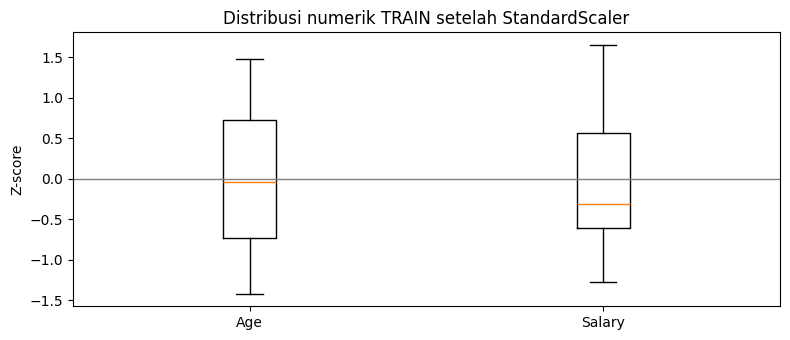

In [14]:
print('Mean train terstandarisasi:', np.round(train_standard.mean(axis=0), 8))
print('Std train (ddof=0)       :', np.round(train_standard.std(axis=0, ddof=0), 8))
print('Mean test terstandarisasi:', np.round(test_standard.mean(axis=0), 8))
assert np.allclose(train_standard.mean(axis=0), 0, atol=1e-10)
assert np.allclose(train_standard.std(axis=0, ddof=0), 1, atol=1e-10)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot([train_standard[:, 0], train_standard[:, 1]], tick_labels=NUM_COLS)
ax.axhline(0, color='grey', linewidth=1)
ax.set_ylabel('Z-score')
ax.set_title('Distribusi numerik TRAIN setelah StandardScaler')
plt.tight_layout()
plt.show()

## G. Membandingkan tiga teknik scaling

| Teknik | Rumus / prinsip | Catatan |
|---|---|---|
| `StandardScaler` | $(x-\mu)/\sigma$ | Mean train ≈ 0 dan standar deviasi train ≈ 1; rentang tidak dibatasi |
| `MinMaxScaler` | $(x-\min)/(\max-\min)$ (default) | Train biasanya 0–1 jika fitur tidak konstan; **test boleh di luar rentang 0–1** |
| `RobustScaler` | $(x-\mathrm{median})/\mathrm{IQR}$ | Lebih tahan nilai ekstrem saat mempelajari parameter, tetapi **tidak menghapus outlier** |

Tiga scaler dibandingkan **setelah imputasi train** pada data yang sama. Ini percobaan konsep, bukan rekomendasi memilih scaler berdasarkan hasil test.

In [15]:
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}
comparison = []
for name, scaler in scalers.items():
    train_scaled = scaler.fit_transform(train_num_imputed)
    test_scaled = scaler.transform(test_num_imputed)
    comparison.append({
        'metode': name,
        'Age_train_min': train_scaled[:, 0].min(),
        'Age_train_max': train_scaled[:, 0].max(),
        'Age_test_min': test_scaled[:, 0].min(),
        'Age_test_max': test_scaled[:, 0].max(),
        'Salary_train_min': train_scaled[:, 1].min(),
        'Salary_train_max': train_scaled[:, 1].max()
    })
result_scaler = pd.DataFrame(comparison).set_index('metode').round(3)
display(result_scaler)

,Age_train_min,Age_train_max,Age_test_min,Age_test_max,Salary_train_min,Salary_train_max
metode,,,,,,
StandardScaler,-1.421,1.475,-0.162,0.720,-1.271,1.653
MinMaxScaler,0.000,1.000,0.435,0.739,0.000,1.000
RobustScaler,-0.957,1.043,-0.087,0.522,-0.821,1.679


### G1. Periksa perubahan satu nilai melalui tiga scaler

Contoh angka `Age` yang sama akan menjadi koordinat berbeda setelah transformasi. Tidak ada jawaban universal bahwa satu scaler selalu terbaik. Pemilihan scaler bergantung pada karakteristik data dan algoritma berikutnya.

In [16]:
index_record = X_train.index[0]
pos_record = X_train.index.get_loc(index_record)
rows = []
for name, scaler in scalers.items():
    converted = scaler.transform(train_num_imputed[[pos_record]])[0]
    rows.append({'scaler': name, 'Age': converted[0], 'Salary': converted[1]})
print('Sampel train yang dibandingkan:', index_record)
print('Nilai setelah imputasi:', train_num_imputed[pos_record])
display(pd.DataFrame(rows).set_index('scaler').round(4))

Sampel train yang dibandingkan: 4
Nilai setelah imputasi: [4.00e+01 5.95e+04]


,Age,Salary
scaler,,
StandardScaler,0.2159,-0.3103
MinMaxScaler,0.5652,0.3286
RobustScaler,0.1739,0.0000


### G2. Ilustrasi sintetis: pengaruh satu nilai ekstrem

Bagian berikut **bukan bagian dari dataset `Data.csv`**. Kita membuat angka kecil `[10, 12, 14, 16, 1000]` untuk menunjukkan bahwa ekstrem dapat memengaruhi mean dan min–max. Contoh ini hanya alat penjelasan, bukan dasar statistik untuk menghapus nilai.

In [17]:
contoh_ekstrem = np.array([[10.], [12.], [14.], [16.], [1000.]])
tabel_ekstrem = pd.DataFrame({'nilai_asli': contoh_ekstrem.ravel()})
for name, estimator in [('Standard', StandardScaler()),
                        ('MinMax', MinMaxScaler()),
                        ('Robust', RobustScaler())]:
    tabel_ekstrem[name] = estimator.fit_transform(contoh_ekstrem).ravel()
print('Data simulasi terpisah, bukan data workshop:')
display(tabel_ekstrem.round(4))

Data simulasi terpisah, bukan data workshop:


,nilai_asli,Standard,MinMax,Robust
0,10.0,-0.5076,0.0000,-1.0
1,12.0,-0.5025,0.0020,-0.5
2,14.0,-0.4975,0.0040,0.0
3,16.0,-0.4924,0.0061,0.5
4,1000.0,2.0000,1.0000,246.5


## H. Kategori: memasukkan One-Hot Encoding ke proses preprocessing

Pada Praktikum 02 mahasiswa sudah belajar bahwa kategori `Country` dapat direpresentasikan sebagai vektor indikator. Di sini fokusnya **bukan mengulang teori fitur**, melainkan memastikan kategori encoder yang dipelajari dari train digunakan konsisten pada test.

`handle_unknown='ignore'` menjaga lebar matriks ketika kategori baru muncul. Kategori yang tidak ada saat `fit` direpresentasikan nol pada seluruh indikator kategori tersebut, sehingga makna baris tersebut harus dievaluasi secara domain.

In [18]:
cat_pipeline_demo = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
cat_train = cat_pipeline_demo.fit_transform(X_train[CAT_COLS])
cat_test = cat_pipeline_demo.transform(X_test[CAT_COLS])
cat_names = cat_pipeline_demo.named_steps['encoder'].get_feature_names_out(CAT_COLS)
print('Fitur kategori yang dipelajari dari TRAIN:', cat_names.tolist())
print('Train:', cat_train.shape, '| Test:', cat_test.shape)
display(pd.DataFrame(cat_train, columns=cat_names, index=X_train.index).sort_index())
display(pd.DataFrame(cat_test, columns=cat_names, index=X_test.index).sort_index())

Fitur kategori yang dipelajari dari TRAIN: ['Country_France', 'Country_Germany', 'Country_Spain']
Train: (7, 3) | Test: (3, 3)


,Country_France,Country_Germany,Country_Spain
1,0.0,0.0,1.0
2,0.0,1.0,0.0
3,0.0,0.0,1.0
4,0.0,1.0,0.0
5,1.0,0.0,0.0
7,1.0,0.0,0.0
8,0.0,1.0,0.0


,Country_France,Country_Germany,Country_Spain
0,1.0,0.0,0.0
6,0.0,0.0,1.0
9,1.0,0.0,0.0


## I. Pipeline final: imputasi + scaling + encoding tanpa leakage

Cara yang dianjurkan adalah menggabungkan operasi menjadi satu objek:

- Cabang numerik: `SimpleImputer(median)` → `StandardScaler()`.
- Cabang kategorikal: `SimpleImputer(most_frequent)` → `OneHotEncoder(handle_unknown='ignore')`.
- `ColumnTransformer`: menerapkan transformasi sesuai kolom.

**Prinsip:** `fit_transform(X_train)` sekali, kemudian **hanya** `transform(X_test)` dan `transform(X_baru)`. Label `y` tidak masuk dalam `ColumnTransformer`.

In [19]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, NUM_COLS),
    ('cat', categorical_pipeline, CAT_COLS)
], remainder='drop', verbose_feature_names_out=True)

X_train_array = preprocessor.fit_transform(X_train)
X_test_array = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

X_train_final = pd.DataFrame(X_train_array, index=X_train.index, columns=feature_names)
X_test_final = pd.DataFrame(X_test_array, index=X_test.index, columns=feature_names)
print('Feature names:', feature_names.tolist())
print('Input train:', X_train.shape, '→ Final train:', X_train_final.shape)
print('Input test :', X_test.shape, '→ Final test :', X_test_final.shape)
print('=== Final feature space: TRAIN ===')
display(X_train_final.sort_index().round(4))
print('=== Final feature space: TEST ===')
display(X_test_final.sort_index().round(4))

Feature names: ['num__Age', 'num__Salary', 'cat__Country_France', 'cat__Country_Germany', 'cat__Country_Spain']
Input train: (7, 3) → Final train: (7, 5)
Input test : (3, 3) → Final test : (3, 5)
=== Final feature space: TRAIN ===


,num__Age,num__Salary,cat__Country_France,cat__Country_Germany,cat__Country_Spain
1,-1.4212,-1.2711,0.0,0.0,1.0
2,-1.0434,-0.7698,0.0,1.0,0.0
3,-0.0360,-0.1850,0.0,0.0,1.0
4,0.2159,-0.3103,0.0,1.0,0.0
5,-0.4138,-0.4356,1.0,0.0,0.0
7,1.2233,1.3188,1.0,0.0,0.0
8,1.4751,1.6530,0.0,1.0,0.0


=== Final feature space: TEST ===


,num__Age,num__Salary,cat__Country_France,cat__Country_Germany,cat__Country_Spain
0,0.7196,0.7340,1.0,0.0,0.0
6,-0.0360,-0.9369,0.0,0.0,1.0
9,-0.1619,0.3163,1.0,0.0,0.0


### I1. Memeriksa parameter yang disimpan pipeline

Setiap tahap menyimpan keadaan (*fitted state*). Kita ambil median, mean, scale, serta kategori dari objek yang sama yang telah digunakan menghasilkan matriks fitur.

In [20]:
fitted_num = preprocessor.named_transformers_['num']
fitted_cat = preprocessor.named_transformers_['cat']
params_num = pd.DataFrame({
    'kolom': NUM_COLS,
    'median_imputer': fitted_num.named_steps['imputer'].statistics_,
    'mean_scaler': fitted_num.named_steps['scaler'].mean_,
    'scale_scaler': fitted_num.named_steps['scaler'].scale_
})
display(params_num.round(4))
print('Kategori hasil fit:')
for name, values in zip(CAT_COLS, fitted_cat.named_steps['encoder'].categories_):
    print(f'  {name} = {values.tolist()}')

,kolom,median_imputer,mean_scaler,scale_scaler
0,Age,38.0,38.2857,7.9411
1,Salary,59500.0,63214.2857,11969.7749


Kategori hasil fit:
  Country = ['France', 'Germany', 'Spain']


### I2. Periksa bentuk dan kelengkapan feature matrix

Untuk dataset ini, jika seluruh tiga kategori negara terwakili dalam train, maka output memiliki **2 fitur numerik + 3 indikator kategori = 5 fitur**. Pemeriksaan otomatis di bawah tidak mengunci jumlah 5 agar tetap berguna jika dataset berubah.

In [21]:
assert X_train_final.shape[0] == len(X_train)
assert X_test_final.shape[0] == len(X_test)
assert X_train_final.columns.equals(X_test_final.columns)
assert X_train_final.notna().all().all() and X_test_final.notna().all().all()
assert np.isfinite(X_train_final.to_numpy(dtype=float)).all()
assert np.isfinite(X_test_final.to_numpy(dtype=float)).all()
print('Checkpoint PASS: ukuran, nama kolom, nilai kosong, dan nilai hingga valid.')
print('Jumlah fitur final:', len(feature_names))
print('Nomor kolom → nama fitur:')
display(pd.DataFrame({'posisi': np.arange(len(feature_names)), 'nama_fitur': feature_names}))

Checkpoint PASS: ukuran, nama kolom, nilai kosong, dan nilai hingga valid.
Jumlah fitur final: 5
Nomor kolom → nama fitur:


,posisi,nama_fitur
0,0,num__Age
1,1,num__Salary
2,2,cat__Country_France
3,3,cat__Country_Germany
4,4,cat__Country_Spain


### I3. Visualisasi matriks fitur setelah preprocessing

Heatmap ini memperlihatkan nilai keluaran yang berbeda skala: angka StandardScaler dapat negatif/lebih dari 1, sedangkan indikator One-Hot tetap 0/1. Warna antarfitur **bukan ukuran kepentingan fitur**.

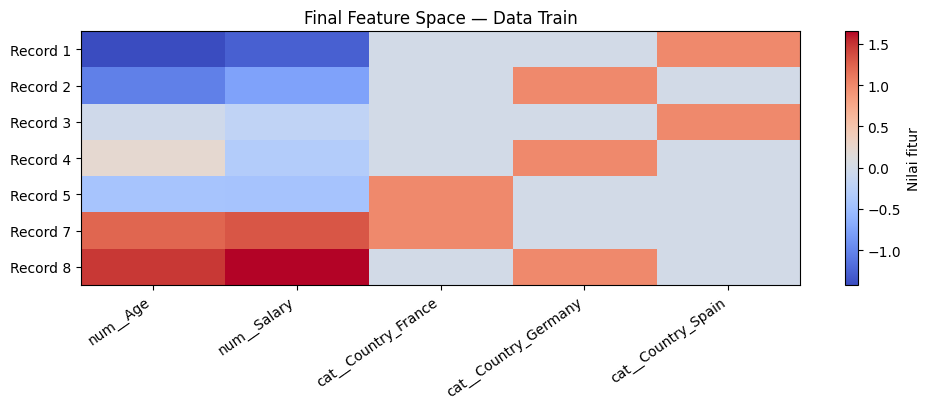

In [22]:
matrix_plot = X_train_final.sort_index()
fig, ax = plt.subplots(figsize=(10, 4.2))
heat = ax.imshow(matrix_plot.to_numpy(), cmap='coolwarm', aspect='auto')
ax.set_xticks(range(matrix_plot.shape[1]), matrix_plot.columns, rotation=35, ha='right')
ax.set_yticks(range(len(matrix_plot)), [f'Record {i}' for i in matrix_plot.index])
ax.set_title('Final Feature Space — Data Train')
fig.colorbar(heat, ax=ax, label='Nilai fitur')
plt.tight_layout()
plt.show()

## J. Menguji data leakage dengan contoh transparan

**Kesalahan:** menghitung statistik preprocessing pada semua baris sebelum split, atau memanggil `fit_transform()` pada test. Kedua pendekatan membuat parameter tidak sesuai skenario model yang menghadapi data baru.

Agar masalah mudah diamati, kita membandingkan median fitur dari train versus keseluruhan dataset. Kode berikut **hanya demonstrasi pelanggaran** dan tidak dipakai menghasilkan matriks final.

In [23]:
median_train = X_train[NUM_COLS].median()
median_all = X[NUM_COLS].median()  # HANYA demonstrasi salah penggunaan
leakage_table = pd.DataFrame({
    'median_train_benar': median_train,
    'median_semua_salah_untuk_fit': median_all,
    'selisih': median_all - median_train
})
display(leakage_table)
print('Pipeline utama tetap di-fit hanya pada train.')

,median_train_benar,median_semua_salah_untuk_fit,selisih
Age,38.0,38.0,0.0
Salary,59500.0,61000.0,1500.0


Pipeline utama tetap di-fit hanya pada train.


### J1. Contoh kebocoran dari MinMaxScaler

Jika test mengandung nilai lebih kecil dari minimum train, `MinMaxScaler` yang benar bisa menghasilkan nilai **negatif**. Hal ini wajar: test diproyeksikan ke skala yang dipelajari dari train. Melakukan `fit` ulang pada test sekadar agar nilainya 0–1 justru merusak konsistensi transformasi.

In [24]:
mm_correct = MinMaxScaler().fit(train_num_imputed)
new_extreme = pd.DataFrame([{'Age': 18., 'Salary': 90000.}])
print('Sampel baru simulasi (hanya untuk menguji batas scaler):')
display(new_extreme)
print('Transformasi dengan parameter train:')
display(pd.DataFrame(mm_correct.transform(new_extreme.to_numpy()), columns=NUM_COLS))
print('Batas train yang dipelajari:', dict(zip(NUM_COLS, mm_correct.data_min_)))
print('Maksimum train yang dipelajari:', dict(zip(NUM_COLS, mm_correct.data_max_)))

Sampel baru simulasi (hanya untuk menguji batas scaler):


,Age,Salary
0,18.0,90000.0


Transformasi dengan parameter train:


,Age,Salary
0,-0.391304,1.2


Batas train yang dipelajari: {'Age': np.float64(27.0), 'Salary': np.float64(48000.0)}
Maksimum train yang dipelajari: {'Age': np.float64(50.0), 'Salary': np.float64(83000.0)}


## K. Inference preprocessing: memproses satu record baru

Prosedur inference harus menerima **kolom dan makna variabel yang sama** dengan training. Sampel `Indonesia` merupakan kategori yang belum muncul di train; `Age` sengaja kosong untuk menunjukkan imputasi menggunakan median train. Tidak ada model prediksi yang dilatih di Praktikum 03.

In [25]:
record_baru = pd.DataFrame([{
    'Country': 'Indonesia',
    'Age': np.nan,
    'Salary': 60000
}], columns=FEATURES)
print('Input record baru:')
display(record_baru)
vector_baru = preprocessor.transform(record_baru)
vector_baru_df = pd.DataFrame(vector_baru, columns=feature_names, index=['record_baru'])
print('Vektor fitur record baru:')
display(vector_baru_df.round(4))
print('Shape:', vector_baru_df.shape)

Input record baru:


,Country,Age,Salary
0,Indonesia,NaN,60000


Vektor fitur record baru:


,num__Age,num__Salary,cat__Country_France,cat__Country_Germany,cat__Country_Spain
record_baru,-0.036,-0.2685,0.0,0.0,0.0


Shape: (1, 5)


### K1. Periksa kategori asing dan perubahan nilai masukan

Encoder `handle_unknown='ignore'` akan memberi nol pada indikator `Country` untuk `Indonesia` (di konfigurasi ini). Bila `Salary` pada record baru diubah, **hanya nilai transformasi numerik yang terkait** yang berubah; parameter train tidak dihitung ulang.

In [26]:
record_ubah = record_baru.copy()
record_ubah.loc[0, 'Salary'] = 75000
v_ubah = pd.DataFrame(preprocessor.transform(record_ubah), columns=feature_names,
                      index=['salary_diubah'])
compare_baru = pd.concat([vector_baru_df, v_ubah])
display(compare_baru.round(4))
print('Median train tersimpan:', fitted_num.named_steps['imputer'].statistics_.tolist())
assert np.allclose(compare_baru[feature_names[2:]].iloc[0],
                   compare_baru[feature_names[2:]].iloc[1])
print('Checkpoint PASS: indikator kategori tidak berubah.')

,num__Age,num__Salary,cat__Country_France,cat__Country_Germany,cat__Country_Spain
record_baru,-0.036,-0.2685,0.0,0.0,0.0
salary_diubah,-0.036,0.9846,0.0,0.0,0.0


Median train tersimpan: [38.0, 59500.0]
Checkpoint PASS: indikator kategori tidak berubah.


### K2. Validasi schema (kolom) dan input sebelum transformasi

`ColumnTransformer` dapat gagal atau menghasilkan interpretasi salah bila kolom hilang, jenis nilai tidak cocok, atau unit input berganti. Contoh validasi sederhana di bawah memeriksa kelengkapan kolom dan tipe numerik. Untuk sistem produksi, validasi harus mencakup rentang masuk akal, kategori, unit, dan aturan bisnis.

In [27]:
def validate_input(record, required_cols=FEATURES):
    missing_cols = [name for name in required_cols if name not in record.columns]
    if missing_cols:
        raise ValueError(f'Kolom belum ada: {missing_cols}')
    checked = record[required_cols].copy()
    for col in NUM_COLS:
        checked[col] = pd.to_numeric(checked[col], errors='raise')
    return checked

checked_record = validate_input(record_baru)
print('Schema valid:', checked_record.columns.to_list())
print('Output shape:', preprocessor.transform(checked_record).shape)

Schema valid: ['Country', 'Age', 'Salary']
Output shape: (1, 5)


## L. Alternatif pipeline menggunakan MinMaxScaler (eksperimen terkontrol)

Untuk memahami perbedaannya, buat pipeline kedua yang **hanya mengganti jenis scaler**. Parameter harus tetap di-*fit* pada `X_train`. Output berbeda pada dua fitur numerik, tetapi indikator kategori dan jumlah kolom seharusnya sama.

In [28]:
preprocessor_minmax = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', MinMaxScaler())
    ]), NUM_COLS),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), CAT_COLS)
])
X_train_minmax = pd.DataFrame(
    preprocessor_minmax.fit_transform(X_train), index=X_train.index,
    columns=preprocessor_minmax.get_feature_names_out()
)
X_test_minmax = pd.DataFrame(
    preprocessor_minmax.transform(X_test), index=X_test.index,
    columns=preprocessor_minmax.get_feature_names_out()
)
print('=== Pipeline alternatif MinMax: TRAIN ===')
display(X_train_minmax.sort_index().round(3))
print('Fitur numerik pada TRAIN berada di 0–1:',
      bool(X_train_minmax.iloc[:, :2].ge(0).all().all() and
           X_train_minmax.iloc[:, :2].le(1).all().all()))
print('Shape standard/minmax:', X_train_final.shape, X_train_minmax.shape)

=== Pipeline alternatif MinMax: TRAIN ===


,num__Age,num__Salary,cat__Country_France,cat__Country_Germany,cat__Country_Spain
1,0.000,0.000,0.0,0.0,1.0
2,0.130,0.171,0.0,1.0,0.0
3,0.478,0.371,0.0,0.0,1.0
4,0.565,0.329,0.0,1.0,0.0
5,0.348,0.286,1.0,0.0,0.0
7,0.913,0.886,1.0,0.0,0.0
8,1.000,1.000,0.0,1.0,0.0


Fitur numerik pada TRAIN berada di 0–1: True
Shape standard/minmax: (7, 5) (7, 5)


### L1. Ringkasan perbandingan StandardScaler versus MinMaxScaler

Perhatikan perbedaan **angka fitur numerik** untuk record train yang sama, bukan perbedaan nama kolom. Praktikum ini tidak memilih metode scaling berdasarkan akurasi, karena pelatihan model baru dilakukan pada praktikum selanjutnya.

In [29]:
idx_compare = X_train.index[0]
compare_scales = pd.DataFrame({
    'Original_imputed': train_num_imputed[X_train.index.get_loc(idx_compare)],
    'StandardScaler': X_train_final.loc[idx_compare, feature_names[:2]].to_numpy(),
    'MinMaxScaler': X_train_minmax.loc[idx_compare, X_train_minmax.columns[:2]].to_numpy()
}, index=NUM_COLS)
print('Record index:', idx_compare)
display(compare_scales.round(4))
assert X_train_final.columns.equals(X_train_minmax.columns)
print('Nama dan urutan fitur identik.')

Record index: 4


,Original_imputed,StandardScaler,MinMaxScaler
Age,40.0,0.2159,0.5652
Salary,59500.0,-0.3103,0.3286


Nama dan urutan fitur identik.


## M. Ekspor matriks hasil preprocessing untuk pemeriksaan

Output CSV di sini merupakan **artefak pembelajaran**. Untuk deployment yang benar, jangan hanya menyimpan CSV; proses preprocessing yang sudah di-*fit* juga harus dipertahankan agar inference memakai transformasi identik. Penyimpanan objek lengkap dibahas pada Praktikum 07.

In [30]:
RESULT_DIR = Path.cwd() / 'hasil_praktikum_03'
RESULT_DIR.mkdir(parents=True, exist_ok=True)
train_export = X_train_final.copy()
train_export['target_Purchased'] = y_train
train_export.to_csv(RESULT_DIR / 'preprocessed_train.csv', index_label='record_asli')
test_export = X_test_final.copy()
test_export['target_Purchased'] = y_test
test_export.to_csv(RESULT_DIR / 'preprocessed_test.csv', index_label='record_asli')
print('Tersimpan di:', RESULT_DIR.resolve())
print('preprocessed_train.csv:', train_export.shape)
print('preprocessed_test.csv :', test_export.shape)
print('Perhatian: objek preprocessor tidak diekspor pada modul ini.')

Tersimpan di: /Users/masaboe/Documents/NGAJAR/ngudiWaluyo2026/final_release/Workshop_From_Data_to_ML/praktikum/notebooks/hasil_praktikum_03
preprocessed_train.csv: (7, 6)
preprocessed_test.csv : (3, 6)
Perhatian: objek preprocessor tidak diekspor pada modul ini.


## N. Latihan pemahaman — kerjakan sebelum membuka jawaban

Tulislah alasan singkat, bukan sekadar jawaban satu kata.

**S1.** Mengapa nilai `NaN` tidak boleh disamakan dengan `0`?  
**S2.** Berapa jumlah baris dan kolom `Data.csv`? Sebutkan fitur dan targetnya.  
**S3.** Apa alasan split dilakukan sebelum imputasi/scaling dalam skenario evaluasi prediksi?  
**S4.** Jelaskan perbedaan `fit`, `transform`, dan `fit_transform`.  
**S5.** Mengapa median dapat dipilih untuk imputasi `Salary`?  
**S6.** Apakah output StandardScaler harus berada di 0–1? Mengapa?  
**S7.** Mengapa nilai test dari MinMaxScaler dapat kurang dari nol atau lebih dari satu?  
**S8.** Apa tujuan `ColumnTransformer` dibanding preprocessing seluruh kolom dengan cara yang sama?  
**S9.** Apa konsekuensi `handle_unknown='ignore'` jika muncul negara baru?  
**S10.** Apakah jumlah kolom train/test boleh berbeda setelah pipeline di-*fit* dengan benar?  
**S11.** Apakah outlier yang ditemukan boxplot harus langsung dihapus? Jelaskan.  
**S12.** Mengapa `Purchased` tidak boleh ikut diinput ke pembentukan `X`?

## O. Latihan praktik kode — 10 tugas

Gunakan variabel yang tersedia dari bagian sebelumnya; jangan menghitung ulang `fit` pada test.

- **P1.** Tampilkan jumlah dan persentase missing values untuk seluruh kolom.
- **P2.** Tampilkan record yang memiliki missing value, beserta kolom mana yang kosong.
- **P3.** Hitung distribusi label train/test sebagai jumlah dan proporsi.
- **P4.** Bentuk tabel median `Age`/`Salary` dari train saja.
- **P5.** Demonstrasikan bahwa test setelah imputasi tidak memiliki `NaN`.
- **P6.** Buat hasil MinMaxScaler untuk test dari parameter train tanpa fit ulang.
- **P7.** Buat tabel feature space final untuk **satu record test** tertentu.
- **P8.** Proses satu record baru dengan `Country='Vietnam'`, `Age` kosong, dan `Salary=55000`.
- **P9.** Uji konsistensi nama dan jumlah fitur train/test dengan `assert`.
- **P10.** Modifikasi pipeline final agar memakai RobustScaler, lalu bandingkan satu record numerik dengan StandardScaler.

## P. Tantangan terapan — 3 studi kasus dengan pembahasan

**T1 — Validasi input.** Seseorang mengirim DataFrame dengan kolom `Country`, `Age`, tetapi tanpa `Salary`. Temukan masalah sebelum inferensi; buat pesan error yang informatif.

**T2 — Leakage.** Seorang mahasiswa melakukan `MinMaxScaler().fit_transform(X_test[['Age','Salary']])` setelah mengimputasi test. Mengapa pendekatan ini salah, dan bagaimana memperbaikinya?

**T3 — Evaluasi keputusan preprocessing.** Ada usulan menghapus record `Salary=83000` karena dianggap outlier, lalu mengklaim hasil model meningkat. Kritik keputusan tersebut berdasarkan konteks data 10 baris, proses evaluasi, dan tahapan praktikum.

## Q. Kunci jawaban dan pembahasan

**Petunjuk pengajar:** Kunci jawaban ditempatkan di akhir untuk menjaga alur *guided inquiry*. Mahasiswa sebaiknya mengerjakan S1–S12, P1–P10, dan T1–T3 terlebih dahulu. Solusi kode sengaja dapat dijalankan ulang setelah seluruh praktik inti.

### Q1. Jawaban konsep S1–S6

1. **S1:** `NaN` berarti nilai tidak tercatat atau belum diketahui, sedangkan `0` adalah nilai numerik tertentu. Mengganti semuanya dengan nol dapat mengubah makna dan distribusi.
2. **S2:** `Data.csv` memiliki **10 baris × 4 kolom**. Fitur: `Country`, `Age`, `Salary`; target: `Purchased`.
3. **S3:** Median, mean, min/max, dan kategori encoder harus dipelajari dari train. Jika test ikut menentukan parameter, evaluasi mengandung informasi yang tidak seharusnya tersedia saat menghadapi data baru.
4. **S4:** `fit` mempelajari parameter, `transform` memakai parameter yang sudah dipelajari, dan `fit_transform` melakukan keduanya pada dataset yang sama. Gunakan `fit_transform` pada train dan `transform` pada test.
5. **S5:** Median lebih robust dibanding mean terhadap nilai ekstrem. Namun, median tetap bukan perbaikan universal dan dapat mengurangi variasi data.
6. **S6:** **Tidak.** StandardScaler melakukan centering/scaling sehingga rentang dapat negatif atau melebihi satu. Yang kira-kira nol dan satu adalah mean dan standar deviasi **train** (bukan test).

### Q2. Jawaban konsep S7–S12

7. **S7:** MinMaxScaler mempelajari min/max train. Jika nilai test di luar rentang train, hasilnya juga di luar rentang 0–1; ini bukan error.
8. **S8:** Jenis fitur memerlukan transformasi berbeda: angka bisa diimputasi dan di-scaling, kategori diimputasi dan di-encode.
9. **S9:** Kategori baru tidak menambah kolom; semua indikator kategori hasil fit pada kategori tersebut menjadi nol. Sistem tidak otomatis memahami kategori baru.
10. **S10:** Dalam pipeline yang sama, jumlah dan urutan fitur train/test seharusnya sama. Jika berbeda, ada kesalahan desain atau transformasi terpisah.
11. **S11:** **Tidak otomatis.** Outlier bisa benar atau salah input. Perlu investigasi domain, dan pada sampel 10 baris penghapusan satu record sangat memengaruhi data.
12. **S12:** `Purchased` adalah target. Menggunakannya sebagai fitur akan membocorkan jawaban prediksi ke algoritma (*target leakage*).

### Q3. Solusi P1–P2: mengaudit missing values

In [31]:
# Jawaban P1 dan P2
missing_answer = pd.DataFrame({
    'missing_n': data.isna().sum(),
    'missing_pct': data.isna().mean().mul(100).round(1)
})
display(missing_answer)
rows_with_na = data[data.isna().any(axis=1)].copy()
rows_with_na['kolom_kosong'] = rows_with_na.apply(
    lambda row: ', '.join(row.index[row.isna()].tolist()), axis=1
)
display(rows_with_na)

,missing_n,missing_pct
Country,0,0.0
Age,1,10.0
Salary,1,10.0
Purchased,0,0.0


,Country,Age,Salary,Purchased,kolom_kosong
4,Germany,40.0,NaN,Yes,Salary
6,Spain,NaN,52000.0,No,Age


**Interpretasi P1–P2:** Kekosongan `Age` dan `Salary` terletak pada baris yang berbeda. Kehilangan satu nilai pada 10 observasi setara dengan 10% untuk kolom yang bersangkutan; angka ini besar secara proporsi, tetapi data tetap terlalu kecil untuk menyimpulkan pola kehilangan.

### Q4. Solusi P3–P4: distribusi label dan median train

In [32]:
# Jawaban P3 dan P4
summary_class = pd.concat([
    y_train.value_counts(normalize=False).rename('jumlah_train'),
    y_train.value_counts(normalize=True).mul(100).rename('pct_train'),
    y_test.value_counts(normalize=False).rename('jumlah_test'),
    y_test.value_counts(normalize=True).mul(100).rename('pct_test')
], axis=1).fillna(0).sort_index()
display(summary_class.round(1))
display(X_train[NUM_COLS].median().rename('median_dari_train').to_frame())

,jumlah_train,pct_train,jumlah_test,pct_test
Purchased,,,,
0,3,42.9,2,66.7
1,4,57.1,1,33.3


,median_dari_train
Age,38.0
Salary,59500.0


### Q5. Solusi P5–P6: imputasi test dan MinMax dari train

In [33]:
# Jawaban P5 dan P6
imputer_solution = SimpleImputer(strategy='median')
tr_clean_sol = imputer_solution.fit_transform(X_train[NUM_COLS])
te_clean_sol = imputer_solution.transform(X_test[NUM_COLS])
assert np.isfinite(te_clean_sol).all()
minmax_solution = MinMaxScaler().fit(tr_clean_sol)
scaled_test_solution = pd.DataFrame(
    minmax_solution.transform(te_clean_sol),
    index=X_test.index, columns=NUM_COLS
)
display(scaled_test_solution.sort_index().round(4))
print('Berhasil: median dan rentang dipelajari hanya dari train.')

,Age,Salary
0,0.7391,0.6857
6,0.4783,0.1143
9,0.4348,0.5429


Berhasil: median dan rentang dipelajari hanya dari train.


### Q6. Solusi P7–P8: satu record test dan record baru

In [34]:
# Jawaban P7 dan P8
idx_test = X_test.index[0]
print('Input record test:', idx_test)
display(X_test.loc[[idx_test]])
display(X_test_final.loc[[idx_test]].round(4))

new_vietnam = pd.DataFrame([{
    'Country': 'Vietnam', 'Age': np.nan, 'Salary': 55000
}], columns=FEATURES)
new_vietnam_encoded = pd.DataFrame(
    preprocessor.transform(new_vietnam), columns=feature_names,
    index=['Vietnam_baru']
)
display(new_vietnam)
display(new_vietnam_encoded.round(4))

Input record test: 0


,Country,Age,Salary
0,France,44.0,72000.0


,num__Age,num__Salary,cat__Country_France,cat__Country_Germany,cat__Country_Spain
0,0.7196,0.734,1.0,0.0,0.0


,Country,Age,Salary
0,Vietnam,NaN,55000


,num__Age,num__Salary,cat__Country_France,cat__Country_Germany,cat__Country_Spain
Vietnam_baru,-0.036,-0.6863,0.0,0.0,0.0


### Q7. Solusi P9–P10: validasi dan RobustScaler

In [35]:
# Jawaban P9
assert X_train_final.shape[1] == X_test_final.shape[1]
assert X_train_final.columns.tolist() == X_test_final.columns.tolist()
print('P9 benar: feature schema konsisten.')

# Jawaban P10: pipeline dibuat ulang, tetapi hanya ganti scaler numerik
robust_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ]), NUM_COLS),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
    ]), CAT_COLS)
])
robust_train = pd.DataFrame(
    robust_preprocessor.fit_transform(X_train), index=X_train.index,
    columns=robust_preprocessor.get_feature_names_out()
)
id_sample = X_train.index[0]
display(pd.DataFrame({
    'StandardScaler': X_train_final.loc[id_sample, feature_names[:2]].to_numpy(),
    'RobustScaler': robust_train.loc[id_sample, robust_train.columns[:2]].to_numpy()
}, index=NUM_COLS).round(4))
assert robust_train.columns.equals(X_train_final.columns)

P9 benar: feature schema konsisten.


,StandardScaler,RobustScaler
Age,0.2159,0.1739
Salary,-0.3103,0.0000


### Q8. Pembahasan T1 — validasi input tidak lengkap

In [36]:
# Jawaban T1
input_tanpa_salary = pd.DataFrame([{'Country': 'France', 'Age': 40}])
try:
    validate_input(input_tanpa_salary)
except ValueError as error:
    print('Contoh pesan validasi:', error)

Contoh pesan validasi: Kolom belum ada: ['Salary']


### Q9. Pembahasan T2 — perbaikan kesalahan leakage

**Kesalahan:** meng-*fit* MinMaxScaler pada test menggunakan distribusi test itu sendiri. Ini membuat representasi data berubah dan memasukkan informasi test ke prosedur transformasi.

**Perbaikan:** `fit()` pada train yang telah diimputasi train; `transform()` pada test yang diimputasi memakai imputer yang sama. Contoh berikut mengulang prinsip tersebut.

In [37]:
# Jawaban T2
imp = SimpleImputer(strategy='median').fit(X_train[NUM_COLS])
train_ready = imp.transform(X_train[NUM_COLS])
test_ready = imp.transform(X_test[NUM_COLS])
sc = MinMaxScaler().fit(train_ready)
train_ready_scaled = sc.transform(train_ready)
test_ready_scaled = sc.transform(test_ready)
print('Train:', train_ready_scaled.shape, 'Test:', test_ready_scaled.shape)
print('Parameter min pada train:', sc.data_min_.tolist())
print('Parameter max pada train:', sc.data_max_.tolist())

Train: (7, 2) Test: (3, 2)
Parameter min pada train: [27.0, 48000.0]
Parameter max pada train: [50.0, 83000.0]


### Q10. Pembahasan T3 — menghapus outlier dan mengklaim perbaikan model

**Kritik yang tepat:**

1. `Salary=83000` adalah nilai dalam dataset yang perlu dievaluasi bersama konteks, bukan otomatis kesalahan.
2. Menghapus satu record dari hanya 10 baris dapat mengubah distribusi fitur dan label secara besar.
3. Ambang outlier yang diputuskan setelah melihat test/hasil prediksi dapat mengakibatkan bias evaluasi.
4. Jika penghapusan memang diperlukan karena kesalahan data yang terdokumentasi, keputusan harus dicatat dan diterapkan melalui prosedur yang dapat direproduksi.
5. Modul 03 belum mengevaluasi model, sehingga klaim peningkatan akurasi **belum dapat dibenarkan**.

**Inti jawaban:** lakukan audit bukti dan sumber terlebih dahulu; jangan menghapus titik data hanya demi memperbaiki angka performa.

## R. Evaluasi mandiri, checklist, dan kesinambungan modul

**Checklist akhir (cek hasil kode):**

- [ ] Dataset asli berhasil dibaca dan struktur kolom dipahami.
- [ ] Missing values, tipe data, duplikat, dan indikasi outlier sudah diaudit.
- [ ] `X` dan `y` dipisahkan serta train/test tidak tumpang tindih.
- [ ] Imputer dan scaler di-*fit* hanya pada train.
- [ ] StandardScaler, MinMaxScaler, dan RobustScaler dapat dibedakan berdasarkan hasil.
- [ ] Pipeline numerik dan kategorikal menghasilkan kolom train/test identik.
- [ ] Record baru dapat ditransformasikan tanpa `fit` ulang.
- [ ] Latihan dan kunci jawaban dapat dijelaskan dengan argumen yang tepat.

**Ringkasan:** `Audit → Split → Fit preprocessing pada train → Transform train/test/data baru → Pemeriksaan schema/output`.

**Lanjutan Praktikum 04 — Klasifikasi KNN:** matriks fitur dari preprocessing adalah masukan algoritma. Pada Praktikum 04, gabungkan preprocessing dan estimator dalam satu pipeline untuk mengevaluasi model tanpa leakage; **jangan membuat klaim performa hanya dari demonstrasi 10 baris ini**.

**Catatan pengajar:** semua jawaban tersedia di bagian Q, sehingga untuk penugasan dapat menyiapkan salinan mahasiswa yang belum menyertakan bagian Q.